# Hotel Booking Demand - Exploratory Data Analysis

Input: `output/analysis_ready_hotel_bookings.csv` (86,638 rows x 46 columns), produced by the ETL pipeline. Run `python pipeline.py` first. All charts are produced by `eda.py` and also saved to `output/eda/`.

**Questions:** When do guests book and stay? What do they pay? Who cancels, and why?

In [1]:
import sys
sys.path.insert(0, '..')
import eda
from IPython.display import Image, display
eda._style()
df = eda.load_data('../output/analysis_ready_hotel_bookings.csv')
eda.OUT = eda.Path('../output/eda')
df.shape

(86638, 46)

In [2]:
df[['hotel','is_cancelled','lead_time','total_nights','total_guests','avg_daily_rate']].describe().round(1)

,is_cancelled,lead_time,total_nights,total_guests,avg_daily_rate
count,86638.0,86638.0,86638.0,86638.0,86638.0
mean,0.3,80.2,3.6,2.0,107.1
std,0.4,85.7,2.7,0.7,51.1
min,0.0,0.0,1.0,1.0,0.0
25%,0.0,12.0,2.0,2.0,72.9
50%,0.0,50.0,3.0,2.0,99.0
75%,1.0,126.0,5.0,2.0,134.4
max,1.0,468.0,26.0,5.0,319.0


## 1. Overview: cancellations and length of stay

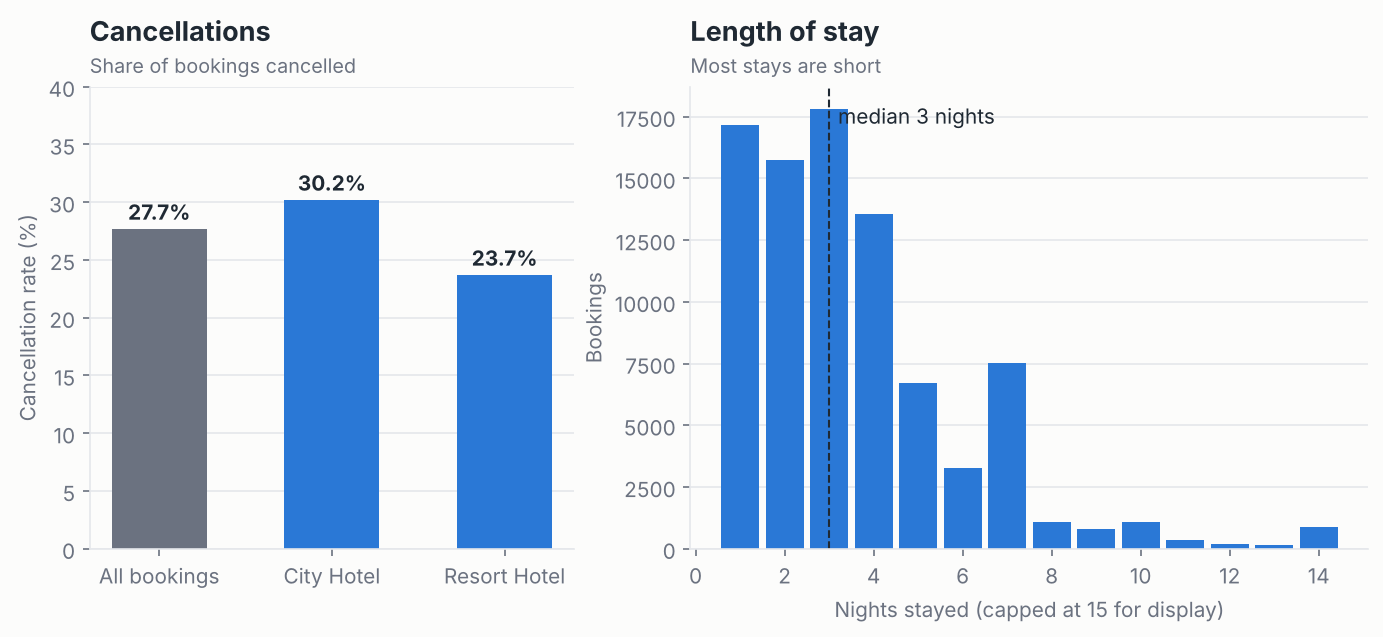

In [3]:
display(Image(eda.plot_overview(df)))

**Insight:** 27.7% of bookings are cancelled; the city hotel (30.2%) cancels more than the resort (23.7%). The median stay is 3 nights and most stays are under a week.

## 2. Bookings over time

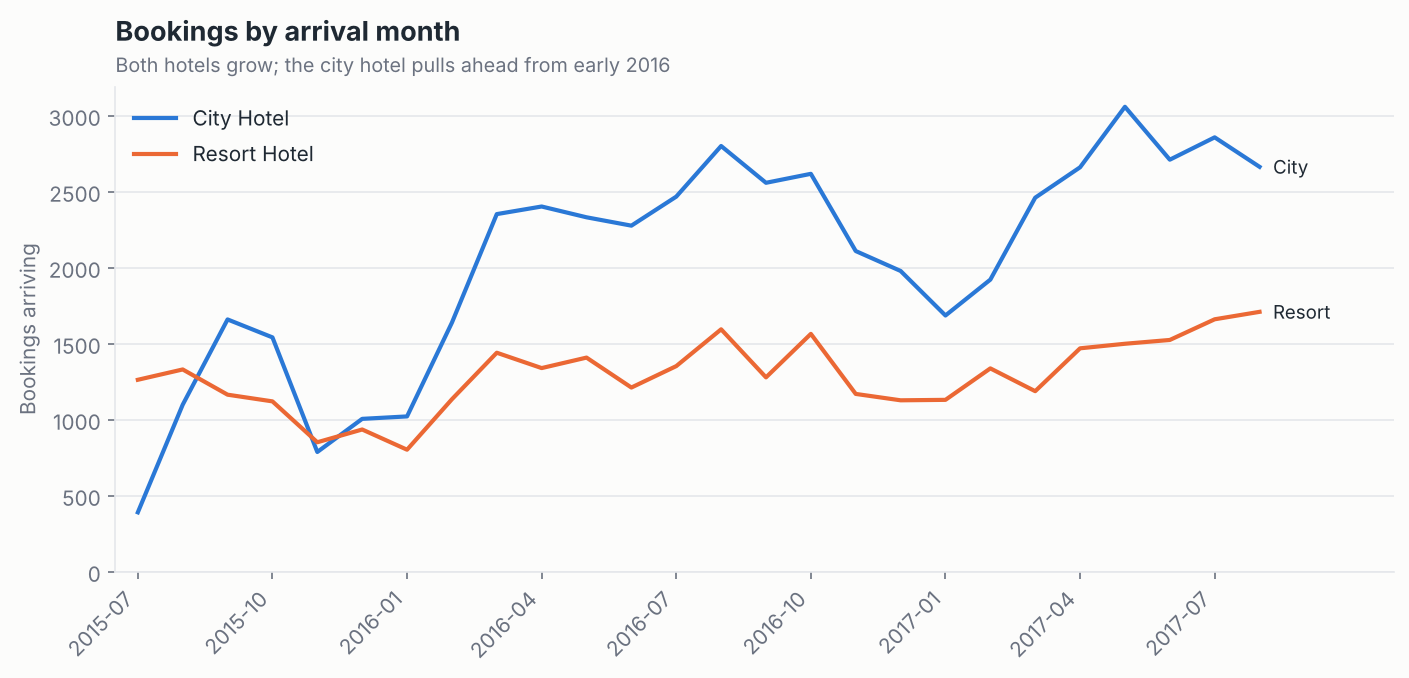

In [4]:
display(Image(eda.plot_monthly_bookings(df)))

**Insight:** Volume grows over the period; the city hotel pulls ahead of the resort from early 2016.

## 3. Price seasonality

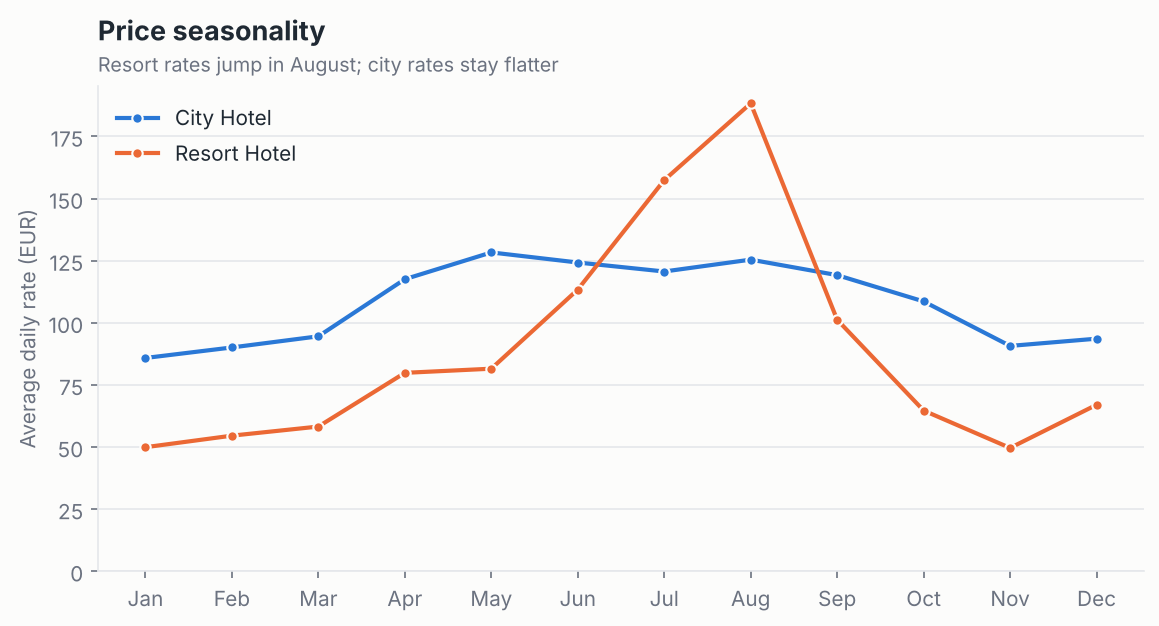

In [5]:
display(Image(eda.plot_price_seasonality(df)))

**Insight:** Resort prices jump from about 50 EUR in winter to about 188 EUR in August; city prices stay in a narrower 86-128 EUR band.

## 4. Distributions

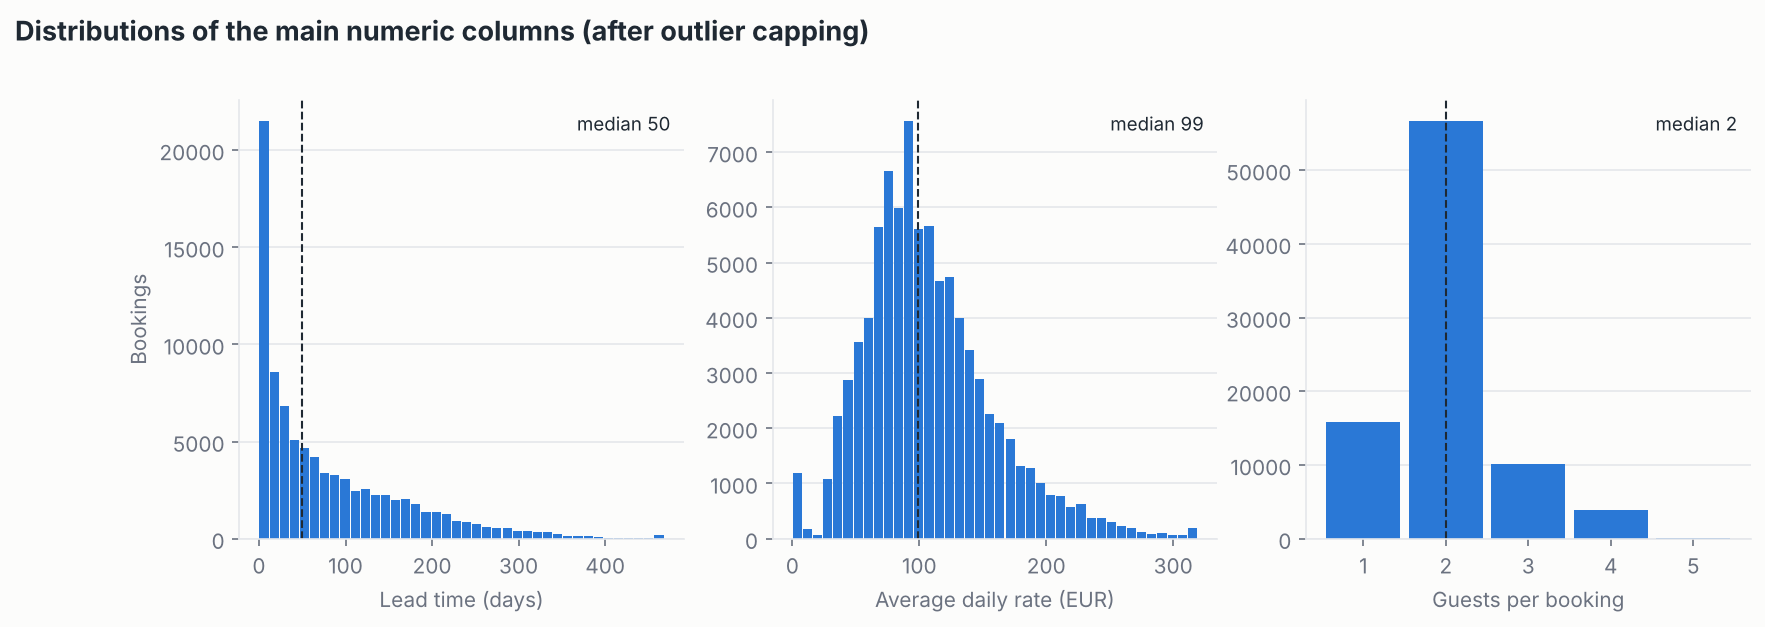

In [6]:
display(Image(eda.plot_distributions(df)))

**Insight:** Lead time is right-skewed (median 50 days, many last-minute bookings). Price is roughly bell-shaped around 99 EUR with a small group of 0 EUR (complimentary) stays. Most bookings are for 2 guests.

## 5. Price spread by hotel

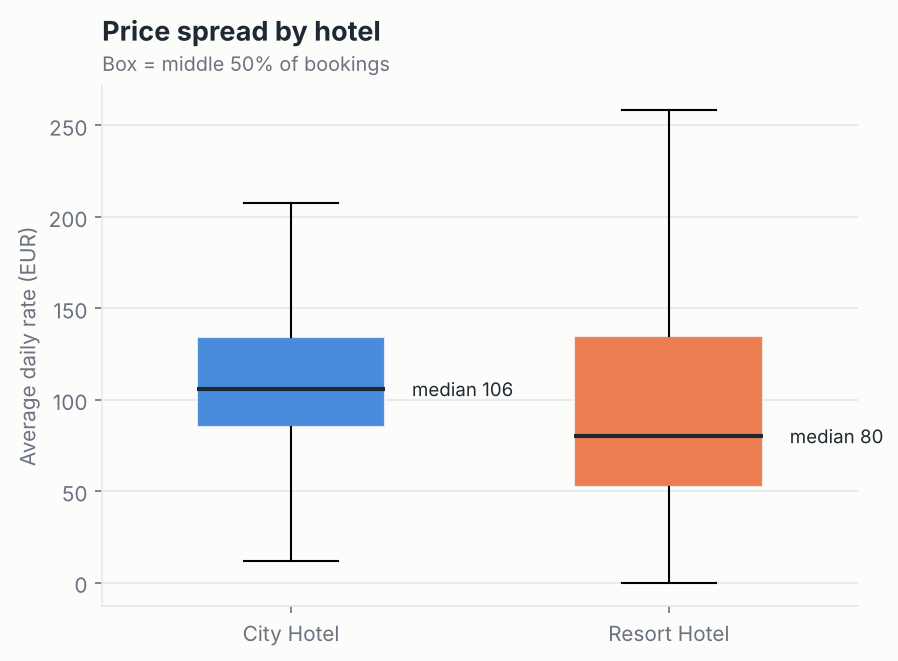

In [7]:
display(Image(eda.plot_price_by_hotel(df)))

**Insight:** The city hotel is more expensive at the median (106 vs 80 EUR) but the resort has the wider spread because of peak-season rates.

## 6. Lead time vs cancellation

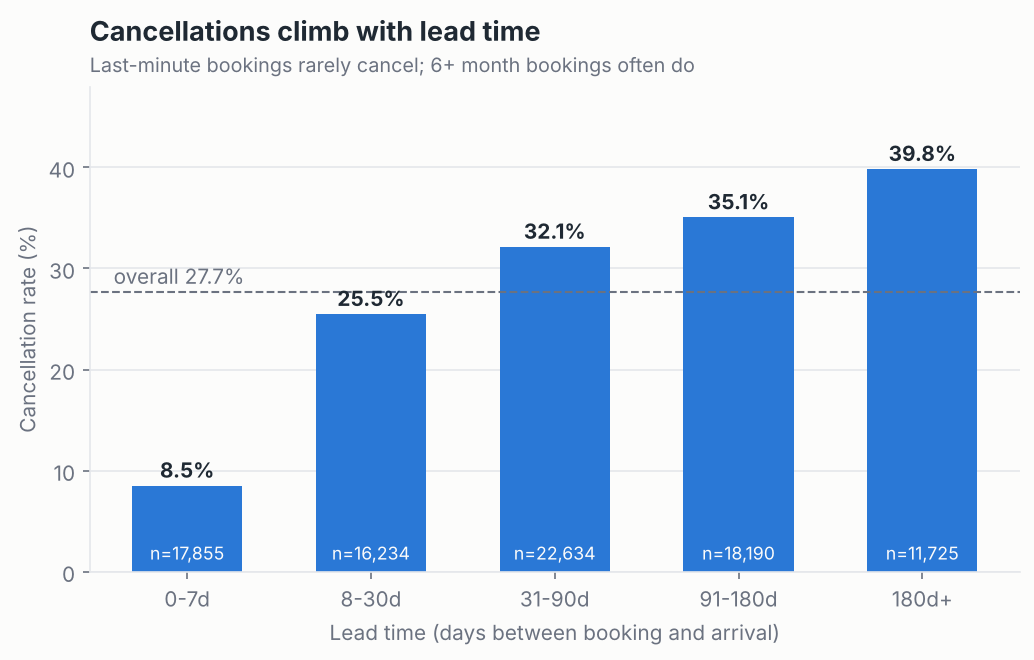

In [8]:
display(Image(eda.plot_cancel_lead_time(df)))

**Insight:** The longer ahead a guest books, the more likely they cancel: 8.5% for 0-7 days versus 39.8% for 180+ days. Lead time is the strongest single behavioural driver.

## 7. Market segment and country

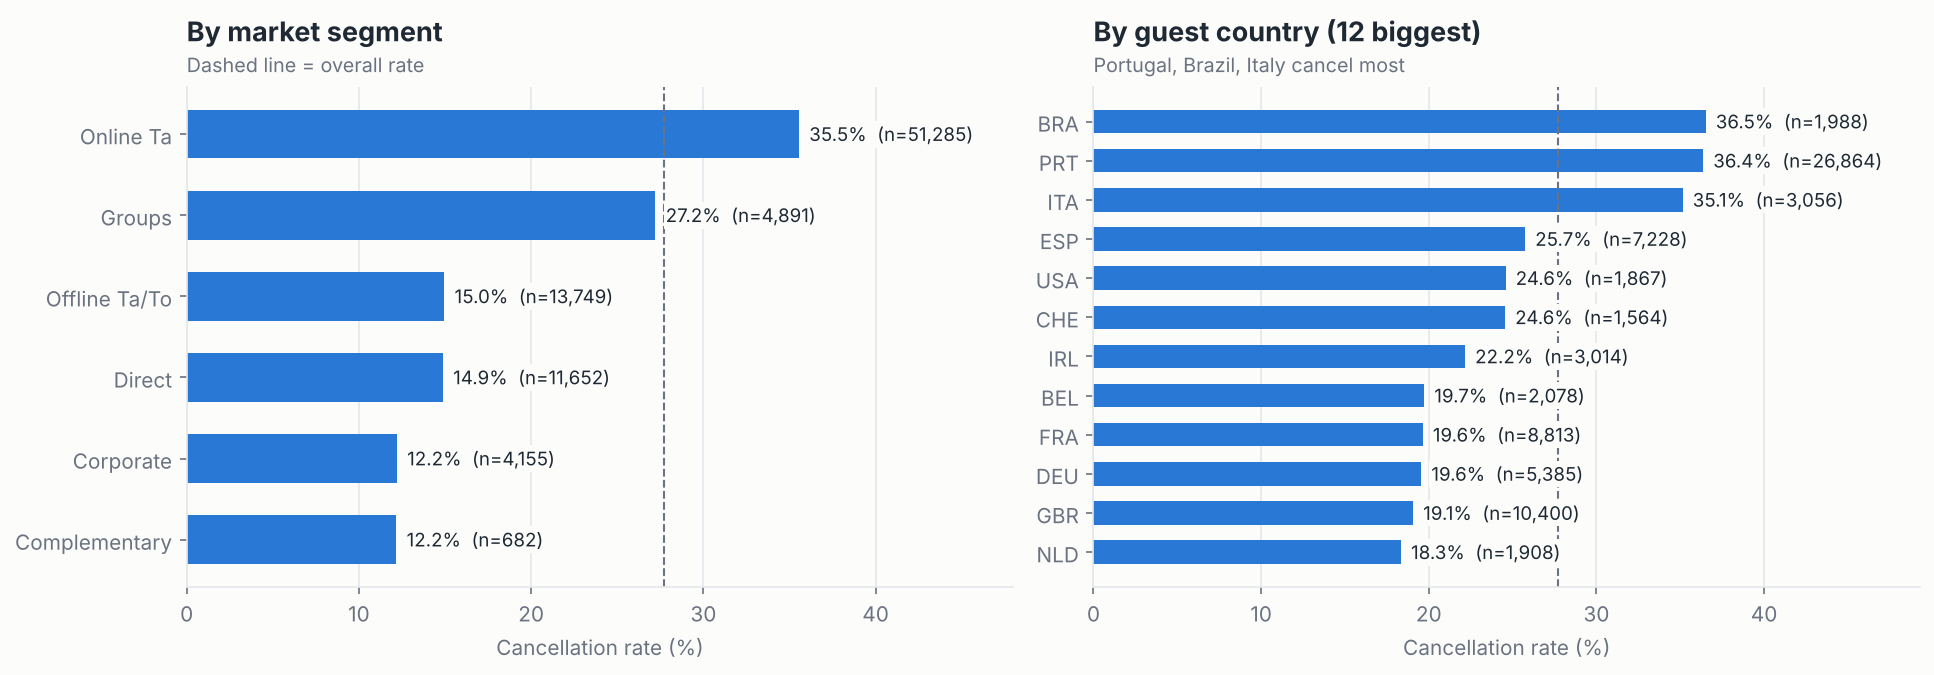

In [9]:
display(Image(eda.plot_cancel_segments(df)))

**Insight:** Online travel agencies (35.5%) cancel far more than direct (14.9%) or corporate (12.2%) bookings. Guests from Portugal, Brazil and Italy cancel most (over 35%).

## 8. Other cancellation signals

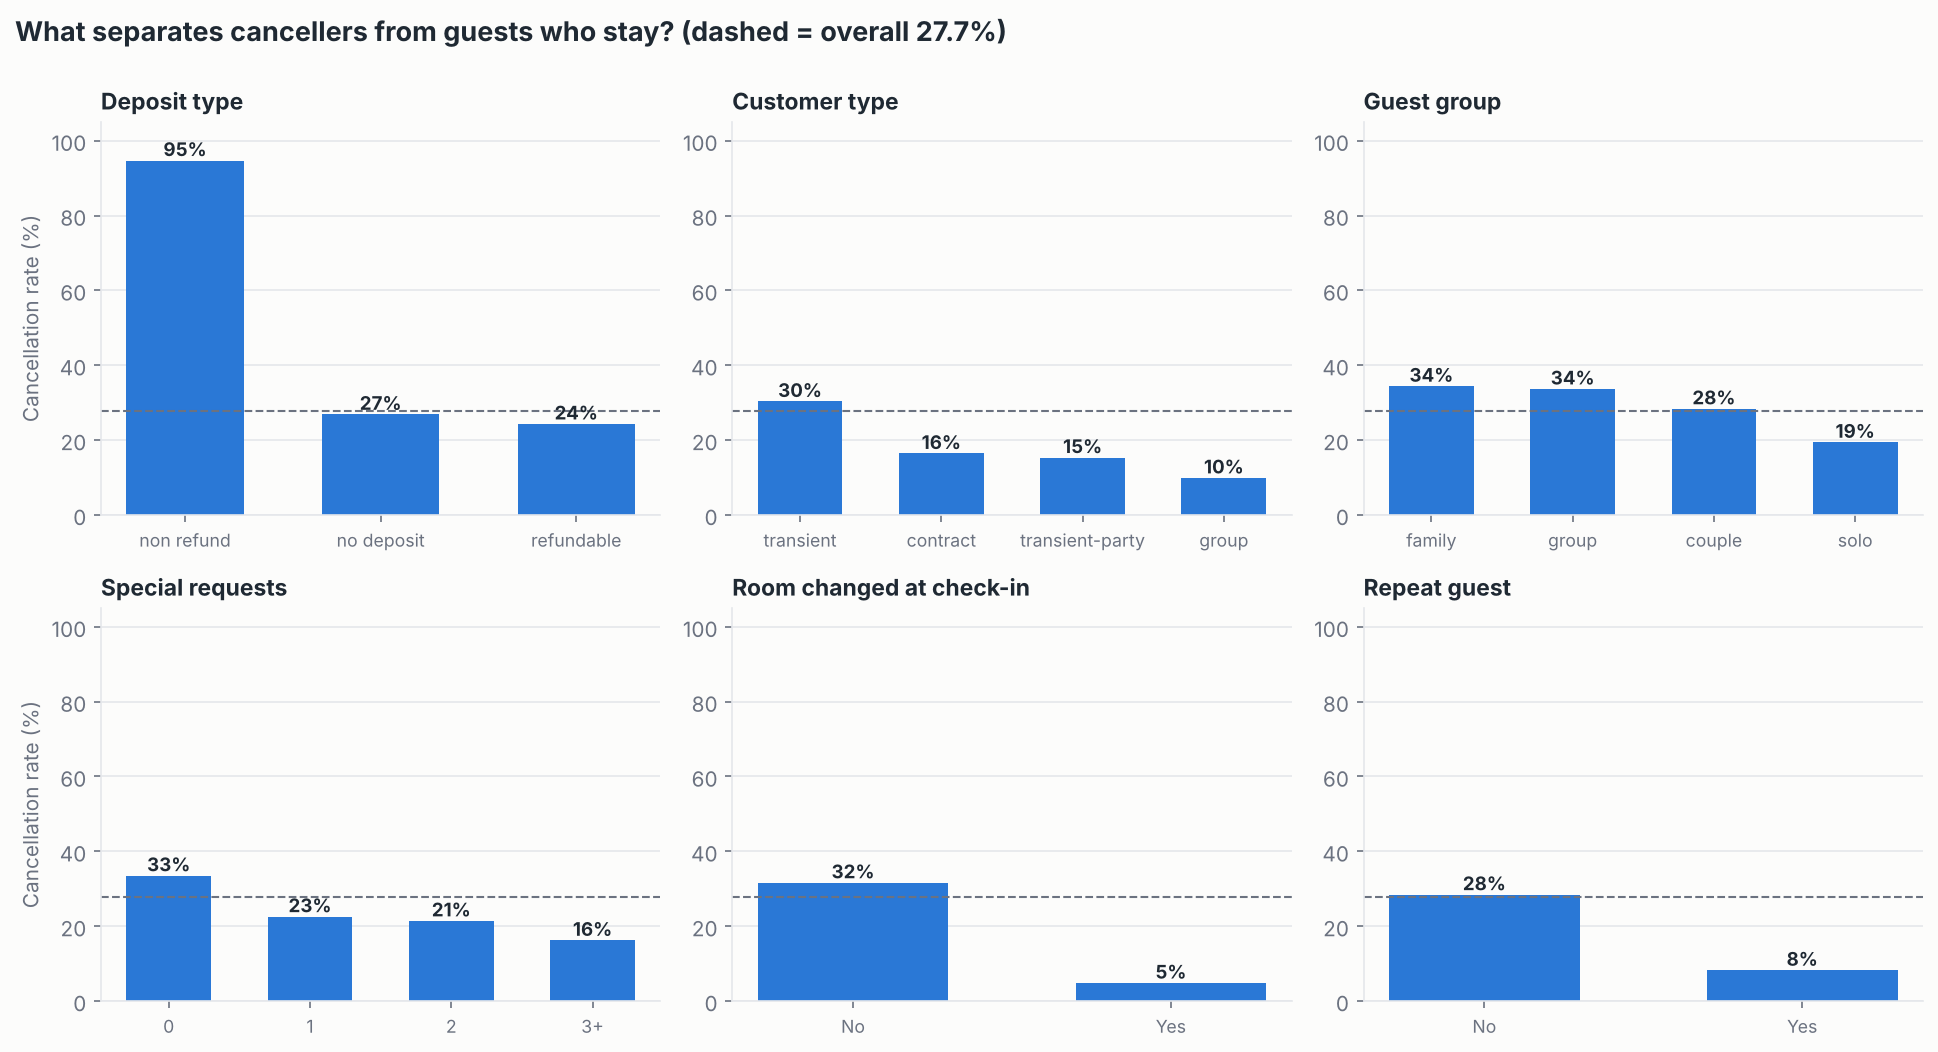

In [10]:
display(Image(eda.plot_cancel_signals(df)))

**Insight:** Non-refundable deposits show 95% cancellations (a surprising pattern, concentrated in group bookings from Portugal and worth investigating). Guests with special requests, repeat guests and bookings whose room changed cancel much less - they are more committed.

## 9. Revenue

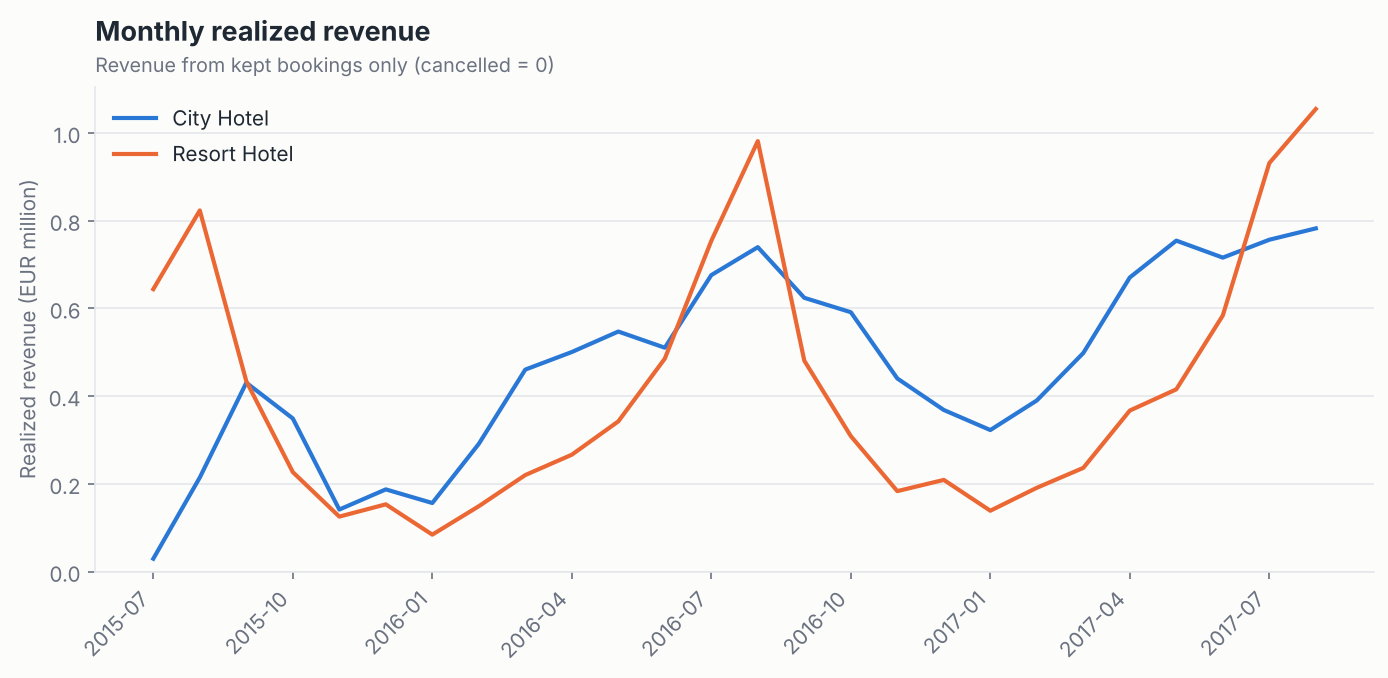

In [11]:
display(Image(eda.plot_revenue(df)))

**Insight:** Realized revenue follows the seasonal peaks, with the resort strongly dependent on summer.

## 10. Correlation

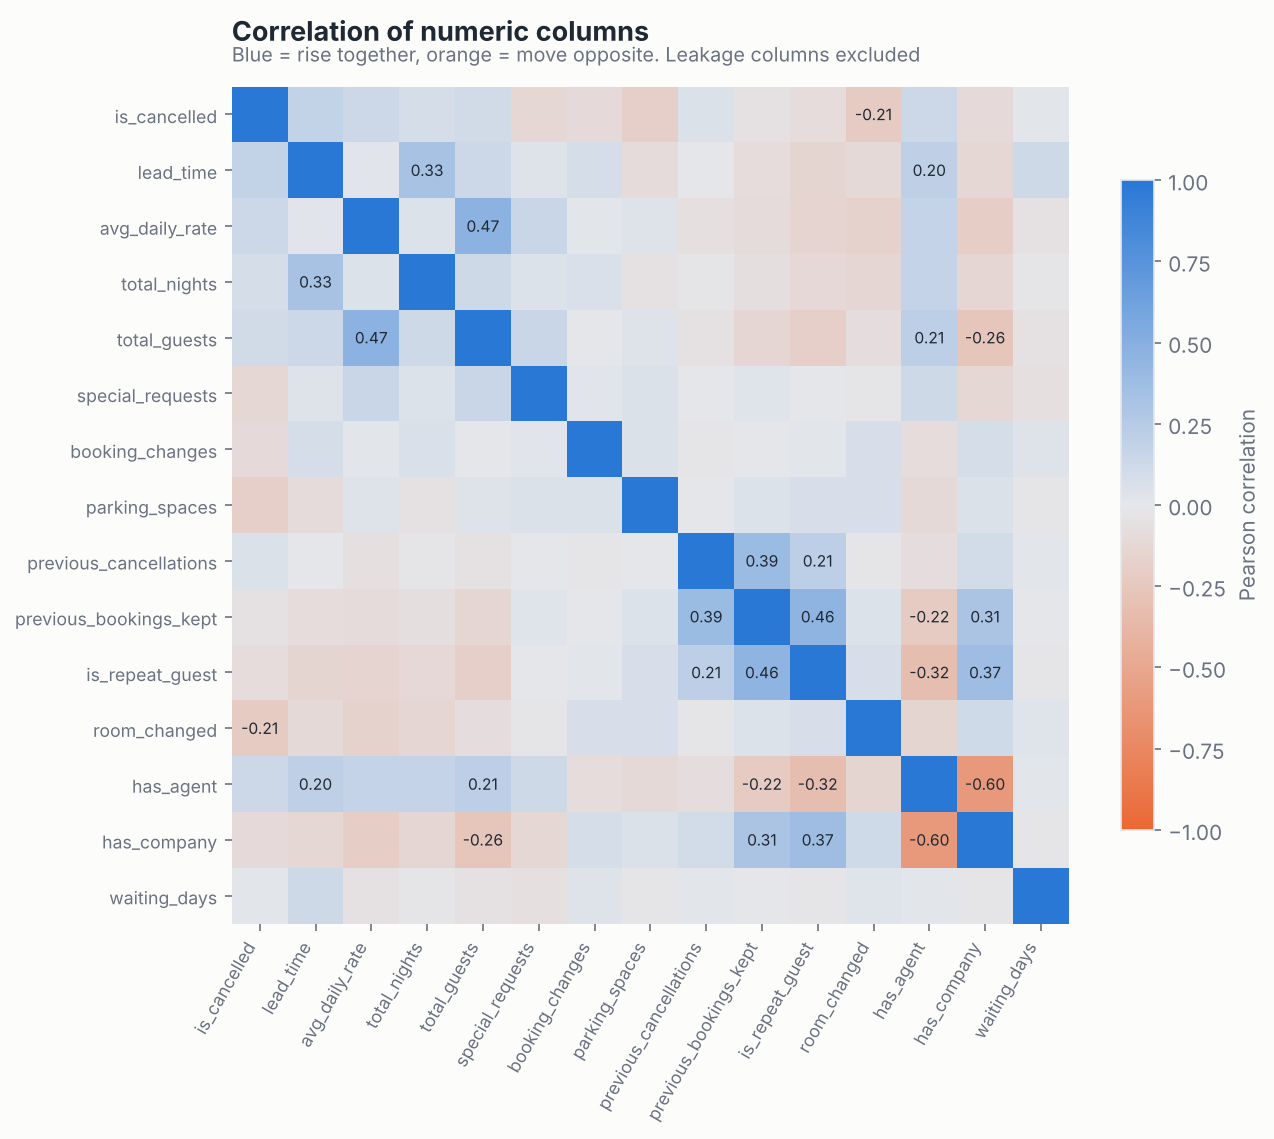

In [12]:
display(Image(eda.plot_correlation(df)))

**Insight:** No single numeric column explains cancellations strongly (lead time +0.18 is the largest). `has_agent` and `has_company` are strongly opposite (-0.60). Leakage columns (`reservation_status`, `realized_revenue`) are excluded on purpose because they are derived from the outcome.

## Conclusions
1. About 1 in 4 bookings is cancelled; **lead time, booking channel and country** matter most.
2. Offering flexible handling for long-lead online-agency bookings (reminders, deposits) would reduce risk.
3. The resort should plan for a strong August peak; the city hotel has steadier demand.
4. Leakage columns must be removed before any cancellation prediction model.